Part A: Load and check the data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [17]:
import pandas as pd

In [18]:
df = pd.read_json('/content/drive/MyDrive/Text Mining_EL/yelp_training_set_review.json', lines=True)
print(df.shape)

(229907, 8)


In [19]:
# Data quality checks
print("Missing values:\n", df.isna().sum(), "\n")

empty = (df['text'].str.strip().str.len() == 0).sum()
print("Empty reviews:", empty)
df = df[df['text'].str.strip().str.len() > 0].reset_index(drop=True)

print("Duplicate review_id:", df['review_id'].duplicated().sum())
print("Duplicate texts:", df['text'].duplicated().sum())
print("Reviews under 3 words:", (df['text'].str.split().str.len() < 3).sum())
print("Date range:", df['date'].min(), "to", df['date'].max())
print("Businesses:", df['business_id'].nunique(), "| Users:", df['user_id'].nunique())
print("\nStar distribution:\n", df['stars'].value_counts().sort_index())

# Remove duplicate texts (so the same review cannot be in both train and test)
before = len(df)
df = df.drop_duplicates(subset='text').reset_index(drop=True)
print("\nRemoved duplicate texts:", before - len(df), "| rows now:", len(df))

Missing values:
 votes          0
user_id        0
review_id      0
stars          0
date           0
text           0
type           0
business_id    0
dtype: int64 

Empty reviews: 6
Duplicate review_id: 0
Duplicate texts: 242
Reviews under 3 words: 540
Date range: 2005-03-07 00:00:00 to 2013-01-05 00:00:00
Businesses: 11537 | Users: 45980

Star distribution:
 stars
1    17516
2    20957
3    35361
4    79875
5    76192
Name: count, dtype: int64

Removed duplicate texts: 242 | rows now: 229659


Part B: Clean the text

In [20]:
import re, string, nltk
nltk.download('wordnet'); nltk.download('omw-1.4')
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

df = df[df['text'].str.strip().str.len() > 0].reset_index(drop=True)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'\d+', ' ', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df['clean_text'] = df['text'].apply(clean_text)

KEEP = {"not", "no", "nor", "never", "nothing", "nobody", "none",
        "cannot", "neither", "without"}
STOP2 = set(ENGLISH_STOP_WORDS) - KEEP
lemmatizer = WordNetLemmatizer()

def preprocess2(text):
    tokens = [t for t in text.split() if t not in STOP2]
    return " ".join(lemmatizer.lemmatize(t) for t in tokens)

df['processed_text2'] = df['clean_text'].apply(preprocess2)
print(df.shape)

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


(229659, 10)


Part C: Explore the data

count    229659.0
mean        130.7
std         114.2
min           1.0
25%          53.0
50%         100.0
75%         172.0
max        1006.0
Name: word_count, dtype: float64


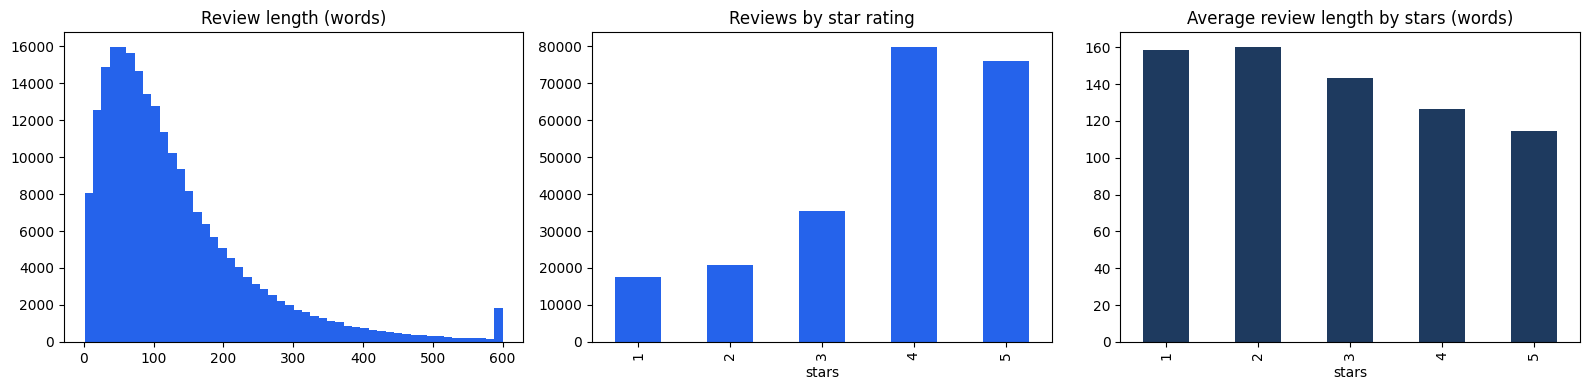

year
2005      101
2006     1216
2007     6667
2008    16984
2009    26643
2010    42539
2011    63736
2012    70322
2013     1451
dtype: int64


In [21]:
import matplotlib.pyplot as plt

df["word_count"] = df["text"].str.split().str.len()
print(df["word_count"].describe().round(1))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].hist(df["word_count"].clip(upper=600), bins=50, color="#2563EB")
ax[0].set_title("Review length (words)")
df["stars"].value_counts().sort_index().plot(kind="bar", ax=ax[1], color="#2563EB")
ax[1].set_title("Reviews by star rating")
ax[1].set_xlabel("stars")
df.groupby("stars")["word_count"].mean().plot(kind="bar", ax=ax[2], color="#1E3A5F")
ax[2].set_title("Average review length by stars (words)")
ax[2].set_xlabel("stars")
plt.tight_layout()
plt.show()

df["year"] = df["date"].dt.year
print(df.groupby("year").size())

Part D: Model, can we detect unhappy reviews?

In [22]:
from sklearn.feature_extraction.text import CountVectorizer
from collections import Counter

def top_words(series, n=15):
    c = Counter(" ".join(series).split())
    return c.most_common(n)

print("Top words in 4-5 star reviews:\n", top_words(df.loc[df.stars >= 4, 'processed_text2']))
print("\nTop words in 1-2 star reviews:\n", top_words(df.loc[df.stars <= 2, 'processed_text2']))

bv = CountVectorizer(ngram_range=(2, 2), stop_words=list(STOP2), max_features=20)
Xb = bv.fit_transform(df.loc[df.stars <= 2, 'processed_text2'])
bigrams = sorted(zip(bv.get_feature_names_out(), Xb.sum(axis=0).A1), key=lambda x: -x[1])
print("\nTop phrases in 1-2 star reviews:\n", bigrams)

Top words in 4-5 star reviews:
 [('place', 111372), ('good', 99607), ('great', 93283), ('not', 88838), ('food', 87114), ('like', 69324), ('time', 65916), ('just', 59697), ('really', 49318), ('love', 45547), ('service', 45450), ('best', 35420), ('nice', 34491), ('little', 33768), ('im', 33499)]

Top words in 1-2 star reviews:
 [('not', 49460), ('food', 30009), ('place', 29087), ('like', 24565), ('just', 24015), ('time', 21533), ('good', 21292), ('no', 19305), ('service', 16532), ('dont', 13653), ('really', 13400), ('didnt', 11374), ('order', 10874), ('got', 10785), ('ordered', 10523)]

Top phrases in 1-2 star reviews:
 [('did not', np.int64(3425)), ('customer service', np.int64(2259)), ('im not', np.int64(2225)), ('not good', np.int64(2158)), ('dont know', np.int64(1801)), ('happy hour', np.int64(1663)), ('tasted like', np.int64(1597)), ('not sure', np.int64(1486)), ('pretty good', np.int64(1248)), ('not worth', np.int64(1205)), ('dont think', np.int64(1111)), ('looked like', np.int64(1

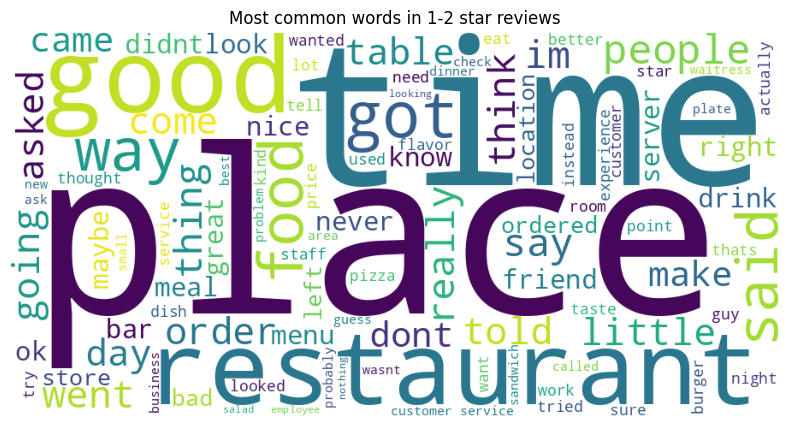

In [23]:
from wordcloud import WordCloud
text_neg = " ".join(df.loc[df.stars <= 2, 'processed_text2'])
wc = WordCloud(width=900, height=450, background_color='white', max_words=100).generate(text_neg)
plt.figure(figsize=(10, 5)); plt.imshow(wc); plt.axis('off')
plt.title("Most common words in 1-2 star reviews"); plt.show()

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# 3-star reviews are removed; 1-2 stars = negative (0), 4-5 stars = positive (1)
df_clf = df[df['stars'] != 3].copy()
df_clf['label'] = (df_clf['stars'] >= 4).astype(int)

X_tr, X_te, y_tr, y_te = train_test_split(
    df_clf['processed_text2'], df_clf['label'],
    test_size=0.2, random_state=42, stratify=df_clf['label'])

tfidf2 = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5)
Xtr = tfidf2.fit_transform(X_tr)
Xte = tfidf2.transform(X_te)

lr2 = LogisticRegression(max_iter=1000, class_weight="balanced")
lr2.fit(Xtr, y_tr)
pred = lr2.predict(Xte)

print("Test reviews:", len(y_te))
print(classification_report(y_te, pred, target_names=["Negative", "Positive"], digits=3))
print("Confusion matrix (rows = actual, cols = predicted):\n", confusion_matrix(y_te, pred))

Test reviews: 38865
              precision    recall  f1-score   support

    Negative      0.789     0.920     0.849      7680
    Positive      0.979     0.939     0.959     31185

    accuracy                          0.935     38865
   macro avg      0.884     0.930     0.904     38865
weighted avg      0.942     0.935     0.937     38865

Confusion matrix (rows = actual, cols = predicted):
 [[ 7064   616]
 [ 1892 29293]]


In [25]:
import numpy as np
feat = np.array(tfidf2.get_feature_names_out())
coef = lr2.coef_[0]
order = np.argsort(coef)
print("Words that push a review towards NEGATIVE:\n", list(feat[order[:25]]))
print("\nWords that push a review towards POSITIVE:\n", list(feat[order[-25:]][::-1]))

Words that push a review towards NEGATIVE:
 ['worst', 'bland', 'mediocre', 'not', 'not worth', 'rude', 'terrible', 'meh', 'disappointing', 'overpriced', 'awful', 'not great', 'horrible', 'not good', 'ok', 'poor', 'disappointed', 'not impressed', 'worse', 'dry', 'tasteless', 'disgusting', 'unfortunately', 'nothing', 'wont']

Words that push a review towards POSITIVE:
 ['great', 'delicious', 'amazing', 'love', 'awesome', 'excellent', 'best', 'fantastic', 'perfect', 'favorite', 'good', 'definitely', 'happy', 'loved', 'friendly', 'yummy', 'wonderful', 'tasty', 'not disappointed', 'yum', 'just right', 'pleased', 'perfectly', 'helpful', 'outstanding']


In [26]:
wrong = y_te.index[(y_te.values != pred)]
fn = [i for i in wrong if y_te[i] == 0]   # actually negative, predicted positive
fp = [i for i in wrong if y_te[i] == 1]   # actually positive, predicted negative
print("Missed negative reviews:", len(fn), "| Wrongly flagged as negative:", len(fp))

print("\n--- NEGATIVE reviews the model missed ---")
for i in pd.Series(fn).sample(5, random_state=1):
    print(f"[{df.loc[i,'stars']} stars] {df.loc[i,'text'][:300]}\n")

Missed negative reviews: 616 | Wrongly flagged as negative: 1892

--- NEGATIVE reviews the model missed ---
[2 stars] J Crew is the proverbial mixed bag.  Maybe I'm spoilt.  When I lived in the Philadelphia area, the King of Prussia team was exceptional.  They knew the true art of selling, which is establishing a connection and offering a variety of choices.  Perhaps the Scottsdale store is simply understaffed or t

[2 stars] Took a galpal here for brunch. It was cute, quaint, tucked away in a strip mall, and had all the earmarks of an amazing find. The case is loaded with fresh baked treats and specialty desserts. Marriages freres tea on the menu? Wow!

My friend ordered the eggs benedict, which looked just like a pictu

[2 stars] HOOD! HOOD! HOOD! customers are super scary. Staff was great.

[2 stars] Small breakfast menu....probably a better place for lunch due to more choices. I got the San Diegan omelet (which the cashier said was their best seller). It was nothing spectacular and

Part E: Complaint themes

In [27]:
neg = df[df['stars'] <= 2].copy().reset_index(drop=True)
print("Negative reviews (1-2 stars):", len(neg))

Negative reviews (1-2 stars): 38398


In [28]:
from sklearn.decomposition import LatentDirichletAllocation

extra = {"place","like","just","really","ive","im","got","went","did","one","get","would","dont"}
stop_list = list(STOP2 | extra)

vec = CountVectorizer(max_features=8000, ngram_range=(1, 2), min_df=20, max_df=0.5, stop_words=stop_list)
X_neg = vec.fit_transform(neg['processed_text2'])

lda = LatentDirichletAllocation(n_components=7, learning_method="online",
                                batch_size=2048, max_iter=10, random_state=42, n_jobs=-1)
lda.fit(X_neg)

words = np.array(vec.get_feature_names_out())
for k, comp in enumerate(lda.components_):
    print(f"Topic {k}:", ", ".join(words[comp.argsort()[-12:][::-1]]))

Topic 0: food, good, restaurant, service, ordered, taco, drink, menu, table, server, mexican, great
Topic 1: no, time, told, said, car, day, never, didnt, service, called, customer, work
Topic 2: pizza, room, people, bar, no, night, time, hotel, good, area, nice, lot
Topic 3: no, coffee, card, said, ice, drink, cream, know, asked, make, cup, time
Topic 4: service, good, time, store, food, location, price, better, great, customer, staff, bad
Topic 5: minute, order, time, table, service, food, wait, came, no, asked, server, took
Topic 6: good, food, chicken, ordered, sauce, salad, burger, cheese, sandwich, no, flavor, taste


In [29]:
themes = {
 "Slow service / waiting": r"\b(?:slow|slowly|forever|waited|waiting|long wait|took a long time|took over|took almost|an hour|wait(?!\s*staff))\b",
 "Rude or unhelpful staff": r"\b(?:rude|rudely|unprofessional|attitude|unfriendly|arrogant|condescending|disrespectful|yelled|screamed|hung up|refused|wouldn.t help|no help|didn.t care|don.t care)\b",
 "Food quality": r"\b(?:bland|stale|dry|overcooked|undercooked|raw|greasy|tasteless|soggy|burnt|burned|disgusting|flavorless|no flavor|lacked flavor|not fresh|tough|rubbery|inedible)\b",
 "Cleanliness and hygiene": r"\b(?:dirty|filthy|roach|roaches|cockroach|bugs? in|food poisoning|unsanitary|unclean|smelly|hair in)\b",
}
keep = list(themes.keys())
low = neg['text'].str.lower()
for name, pattern in themes.items():
    neg[name] = low.str.contains(pattern, regex=True)

rows = []
for t in keep:
    m = neg[t]
    rows.append({"theme": t,
                 "reviews": int(m.sum()),
                 "share_of_negatives_%": round(100 * m.mean(), 1),
                 "pct_1star_%": round(100 * (neg.loc[m, 'stars'] == 1).mean(), 1)})
theme_table = pd.DataFrame(rows)
print(theme_table.to_string(index=False))
print("\nNegative reviews matching NO theme: %.1f%%" % (100 * (~neg[keep].any(axis=1)).mean()))

                  theme  reviews  share_of_negatives_%  pct_1star_%
 Slow service / waiting     8759                  22.8         47.4
Rude or unhelpful staff     4515                  11.8         61.8
           Food quality     9011                  23.5         41.9
Cleanliness and hygiene     2064                   5.4         59.0

Negative reviews matching NO theme: 49.6%


In [34]:
for t in keep:
    print("=" * 80, "\n", t, "\n", "=" * 80)
    s = neg[neg[t]].sample(8, random_state=3)
    for n, txt in enumerate(s['text'], 1):
        print(f"{n}. {txt[:900]}\n")

 Slow service / waiting 
1. I've heard great things about the food but I was disappointed. We had a reservation, arrived on time but were not seated for 20 minutes. Service was friendly and knowledgable but it took forever to get our entrees - about 45 minutes AFTER our appetizer was finished and gone. I ordered Steak Oscar and I'm pretty sure they had grill running WAY too hot - my steak was crispified on the outside and rare on the inside. The desserts were the highlight of the meal and they had a good selection of wines by the glass. My first impression: overpriced and overrated.

2. Oh @TheVigAZ, you usually do so well, but when you fail me, it's always an epic fail. Last night, you fell flat on your face.

I ordered the Vigazz Burger, anticipating greatness.

My girlfriend and her daughter received their food, and finished their meals. I got nothing.

While my girlfriend was still eating, I inquired with one of the back servers about my burger, and was told it was almost ready.

1

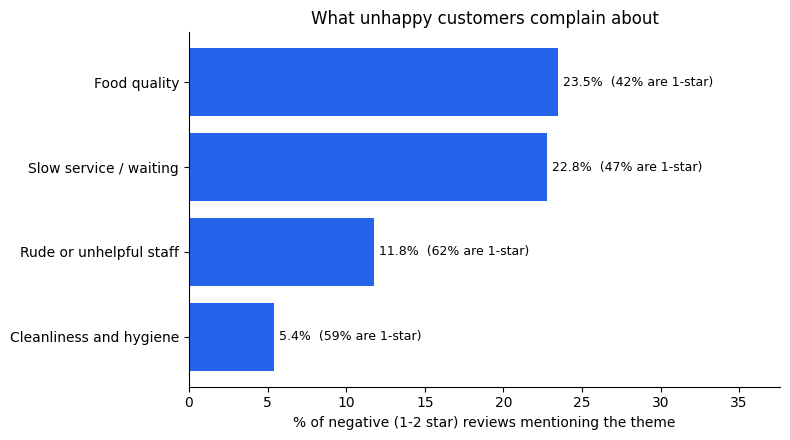

In [31]:
import os
os.makedirs("outputs", exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 4.5))
tt = theme_table.sort_values("share_of_negatives_%")
bars = ax.barh(tt["theme"], tt["share_of_negatives_%"], color="#2563EB")
for b, p in zip(bars, tt["pct_1star_%"]):
    ax.text(b.get_width() + 0.3, b.get_y() + b.get_height() / 2,
            f"{b.get_width():.1f}%  ({p:.0f}% are 1-star)", va='center', fontsize=9)
ax.set_xlabel("% of negative (1-2 star) reviews mentioning the theme")
ax.set_title("What unhappy customers complain about")
ax.set_xlim(0, tt["share_of_negatives_%"].max() * 1.6)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig("outputs/complaint_themes.png", dpi=200)
plt.show()

Part F: Extra analysis

      Slow service / waiting  Rude or unhelpful staff  Food quality  \
year                                                                  
2005                    16.7                      0.0           0.0   
2006                    16.4                      5.5          15.2   
2007                    22.2                      8.0          21.6   
2008                    21.4                      8.9          24.1   
2009                    22.5                      9.4          25.7   
2010                    22.7                     11.3          24.9   
2011                    22.5                     11.4          23.4   
2012                    23.5                     13.8          22.2   
2013                    24.5                     16.2          17.0   

      Cleanliness and hygiene  n_reviews  
year                                      
2005                      0.0          6  
2006                      6.7        165  
2007                      5.1        758  
200

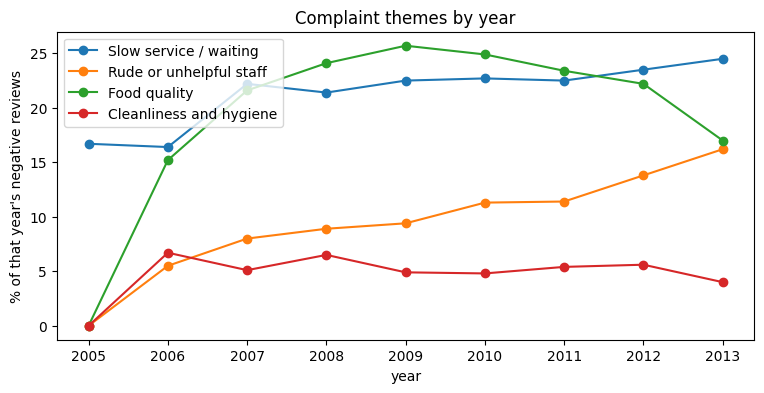

In [32]:
neg['year'] = neg['date'].dt.year
trend = neg.groupby('year')[keep].mean().mul(100).round(1)
trend['n_reviews'] = neg.groupby('year').size()
print(trend)
trend[keep].plot(figsize=(9, 4), marker='o')
plt.ylabel("% of that year's negative reviews"); plt.title("Complaint themes by year"); plt.show()

In [33]:
# Among unhappy reviews: does a theme make a 1-star (angriest) review more likely?
y1 = (neg['stars'] == 1).astype(int)
Xf = neg[keep].astype(int)
lg = LogisticRegression(max_iter=1000).fit(Xf, y1)
odds = pd.DataFrame({"theme": keep, "odds_ratio": np.exp(lg.coef_[0]).round(2)})
print("Baseline share of 1-star among negatives: %.1f%%" % (100 * y1.mean()))
print(odds.to_string(index=False))

Baseline share of 1-star among negatives: 45.5%
                  theme  odds_ratio
 Slow service / waiting        1.06
Rude or unhelpful staff        2.08
           Food quality        0.85
Cleanliness and hygiene        1.79
